# 可视化绘图 #
- 依据过滤后的数据绘制折线图，尝试直观展示趋势变化

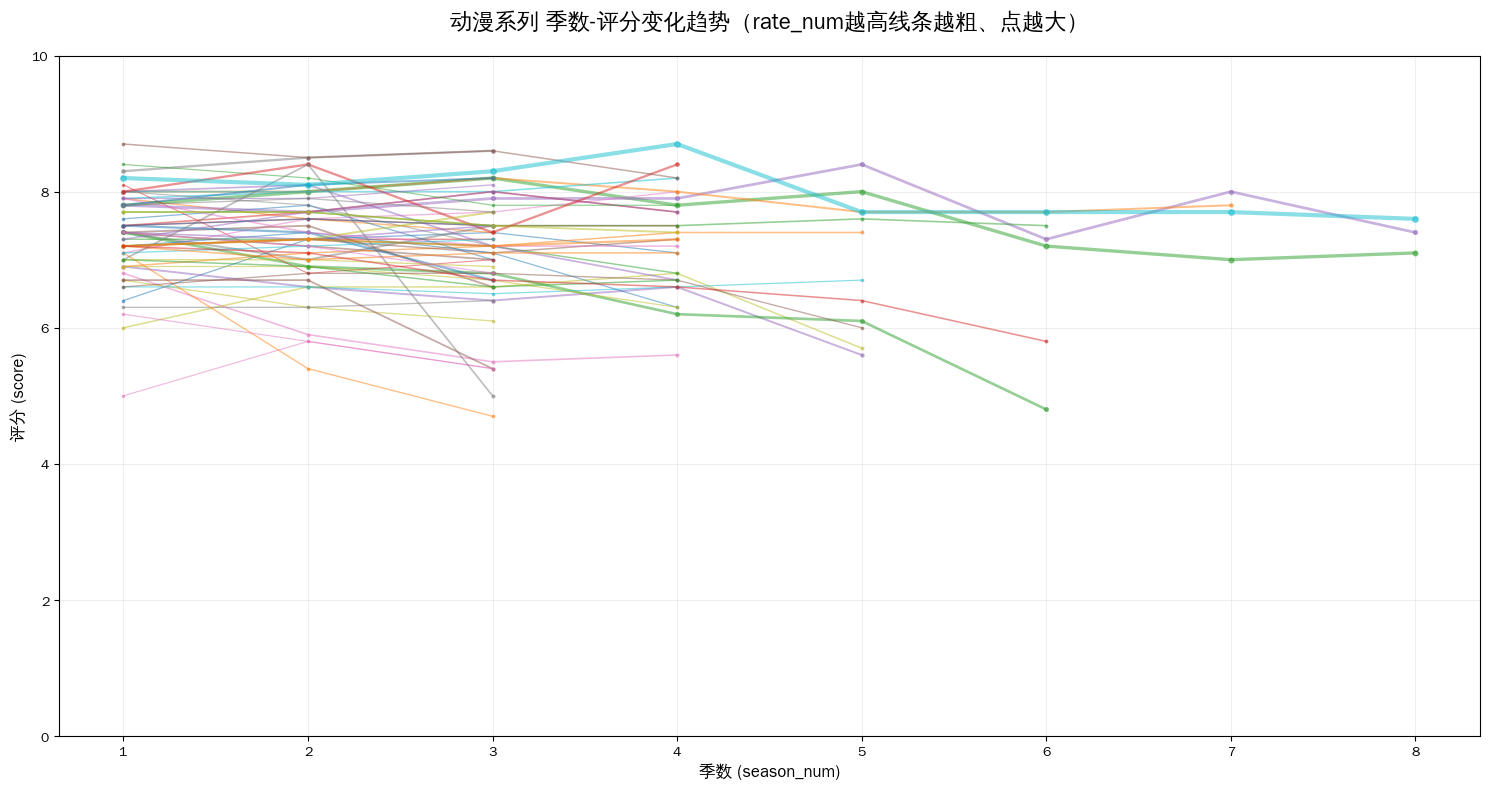

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

#导入（这里导入的是过滤后数据）
df = pd.read_csv("../data/processed/filtered_data.csv")

# ===== 基础配置与处理 =====
plt.rcParams['font.sans-serif'] = ['WenQuanYi Zen Hei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(15, 8))

#按系列聚合rate_num
series_rate_num = df.groupby("series_name")["rate_num"].sum()  # 也可替换为mean()/max()
#原生min-max归一化
min_rate = series_rate_num.min()
max_rate = series_rate_num.max()
#处理极端情况：如果所有rate_num都相同，避免除以0
if max_rate == min_rate:
    series_linewidth = {name: 0.8 for name in series_rate_num.index}
    series_markersize = {name: 3 for name in series_rate_num.index}
else:
    # 线条宽度归一化到[0.8, 3]
    series_linewidth = (
        (series_rate_num - min_rate) / (max_rate - min_rate) * (3 - 0.8) + 0.8
    ).to_dict()
    # 标记点大小归一化到[3, 8]（和线条宽度同步变化）
    series_markersize = (
        (series_rate_num - min_rate) / (max_rate - min_rate) * (8 - 3) + 3
    ).to_dict()


# ===== 遍历每个动漫系列绘制折线 =====
for series_name, group in df.groupby("series_name"):
    # 由于数据已排序，可直接取数（额外排序兜底，避免意外）
    group_sorted = group.sort_values("season_num")
    x = group_sorted["season_num"]
    y = group_sorted["score"]
    # 动态获取线条宽度和标记点大小
    line_width = series_linewidth[series_name]
    marker_size = series_markersize[series_name]
    # 绘制折线：线条粗细和标记点大小都随rate_num变化
    plt.plot(
        x, y,
        marker=".",  # 小点标记
        markersize=marker_size,  # 动态标记点大小
        linewidth=line_width,   # 动态线条宽度
        alpha=0.5,  # 半透明，核心优化点
        label=series_name
    )

# ===== 图表美化与标注 =====
plt.title("动漫系列 季数-评分变化趋势（rate_num越高线条越粗、点越大）", fontsize=16, pad=20)
plt.xlabel("季数 (season_num)", fontsize=12)
plt.ylabel("评分 (score)", fontsize=12)
# 添加网格，辅助看数值
plt.grid(True, alpha=0.2, linestyle="-")
# 限制y轴范围（假设评分是0-10，可根据实际调整）
plt.ylim(bottom=0, top=10)
# 276个系列图例会完全遮挡图表，默认关闭
# plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
# 自动调整布局，避免标签被截断
plt.tight_layout()


# ===== 显示图表 =====
plt.show()

# （可选）导出图片 #
- 想导出图片的话，运行下一个cell，图片将会导出到../figures

In [ ]:
plt.savefig("../figures/rating_trend.png", dpi=300, bbox_inches="tight")